In [1]:
import pandas as pd
import numpy as np
df = pd.read_parquet("../data/model_sample.parquet")
train = df[df["sample"] == "train"].copy()

In [4]:
import sys
sys.path.append("..")
from src.features import get_candidate_features, late_added_cols

candidate_features = get_candidate_features(df)
len(candidate_features)

61

In [5]:
train[late_added_cols].isna().groupby(train["year"]).mean().round(2).T

year,2013,2014,2015
open_acc_6m,1.0,1.0,0.95
open_act_il,1.0,1.0,0.95
open_il_12m,1.0,1.0,0.95
open_il_24m,1.0,1.0,0.95
mths_since_rcnt_il,1.0,1.0,0.95
total_bal_il,1.0,1.0,0.95
il_util,1.0,1.0,0.95
open_rv_12m,1.0,1.0,0.95
open_rv_24m,1.0,1.0,0.95
max_bal_bc,1.0,1.0,0.95


In [6]:
pd.set_option("display.max_rows", 100)
train[candidate_features].isna().groupby(train["year"]).mean().round(2).T

year,2013,2014,2015
loan_amnt,0.00,0.00,0.00
emp_length,0.05,0.06,0.07
home_ownership,0.00,0.00,0.00
annual_inc,0.00,0.00,0.00
verification_status,0.00,0.00,0.00
purpose,0.00,0.00,0.00
dti,0.00,0.00,0.00
delinq_2yrs,0.00,0.00,0.00
earliest_cr_line,0.00,0.00,0.00
fico_range_low,0.00,0.00,0.00


Finding: ~35 bureau fields are ~52% missing in 2012 and fully populated from 2013 — LC began reporting them mid-2012. Rather than treat “not yet collected” as a borrower signal, the training window starts in 2013. Train = 2013–2015 (~546k loans).

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

train["fico_band"] = pd.cut(train["fico_range_low"],
                            bins=[660, 680, 700, 720, 740, 780, 850],
                            right=False)

fico_summary = train.groupby("fico_band", observed=True)["default"].agg(["mean", "count"])
fico_summary

,mean,count
fico_band,,
"[660, 680)",0.182243,201769
"[680, 700)",0.148675,150119
"[700, 720)",0.112378,97074
"[720, 740)",0.083976,48490
"[740, 780)",0.062711,35847
"[780, 850)",0.040310,12627


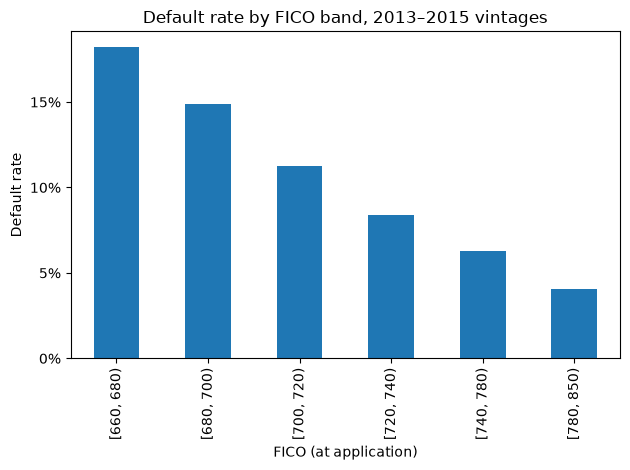

In [ ]:
ax = fico_summary["mean"].plot(kind="bar")
ax.set_ylabel("Default rate")
ax.set_xlabel("FICO (at application)")
ax.set_title("Default rate by FICO band, 2013–2015 vintages")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05)
plt.tight_layout()
plt.show()

In [50]:
train["dti_band"] = pd.qcut(train["dti"], 10, precision=0)

dti_summary = train.groupby("dti_band", observed=True)["default"].agg(["mean", "count"])
dti_summary

,mean,count
dti_band,,
"(-1.0, 7.0]",0.105588,54599
"(7.0, 10.0]",0.110549,54727
"(10.0, 13.0]",0.112950,54511
"(13.0, 15.0]",0.121466,54649
"(15.0, 17.0]",0.131434,54552
"(17.0, 20.0]",0.140365,54679
"(20.0, 22.0]",0.148413,54463
"(22.0, 25.0]",0.160761,54584
"(25.0, 29.0]",0.176156,54639


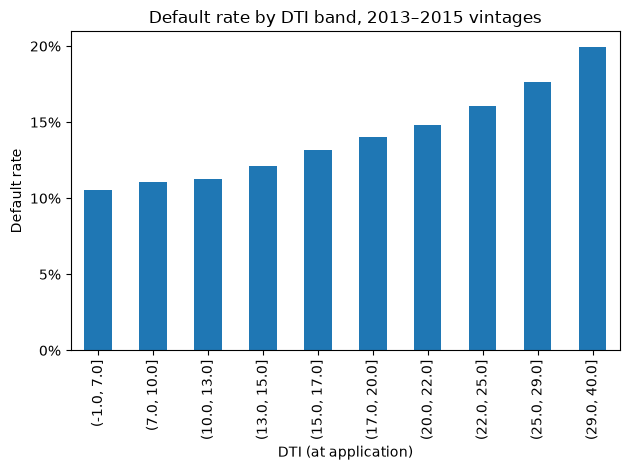

In [51]:
ax = dti_summary["mean"].plot(kind="bar")
ax.set_ylabel("Default rate")
ax.set_xlabel("DTI (at application)")
ax.set_title("Default rate by DTI band, 2013–2015 vintages")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05))
plt.tight_layout()
plt.show()

In [ ]:
purpose_summary = (train.groupby("purpose")["default"]
                   .agg(["mean", "count"])
                   .sort_values("mean"))
purpose_summary

,mean,count
purpose,,
educational,0.000000,1
credit_card,0.117525,136822
car,0.121142,5184
home_improvement,0.126704,31246
major_purchase,0.135022,10065
wedding,0.138672,512
debt_consolidation,0.147367,313313
vacation,0.158557,3658
other,0.164086,28156


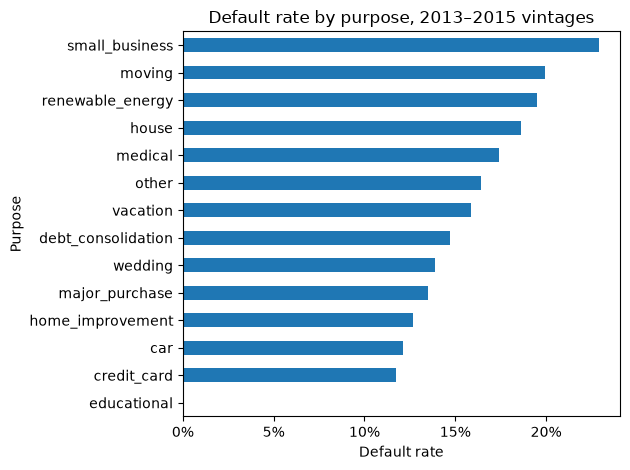

In [46]:
ax = purpose_summary["mean"].plot(kind="barh")
ax.set_xlabel("Default rate")
ax.set_ylabel("Purpose")
ax.set_title("Default rate by purpose, 2013–2015 vintages")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout()
plt.show()

In [44]:
home_ownership_summary = (train.groupby("home_ownership")["default"]
                          .agg(["mean", "count"])
                          .sort_values("mean"))

home_ownership_summary = home_ownership_summary[home_ownership_summary["count"] >= 1000]
home_ownership_summary

,mean,count
home_ownership,,
MORTGAGE,0.114463,256161
OWN,0.149829,56985
RENT,0.167408,232778


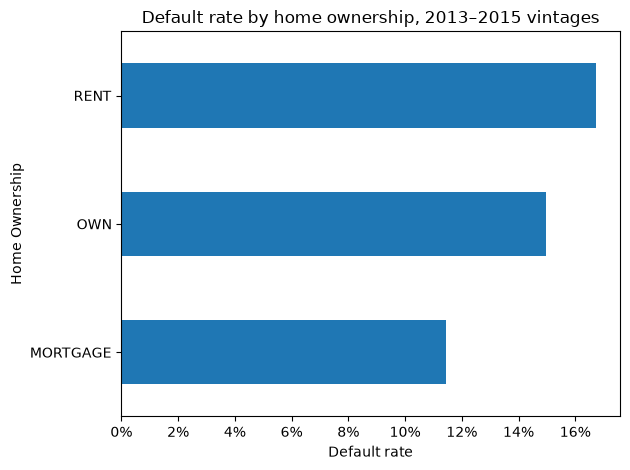

In [45]:
ax = home_ownership_summary["mean"].plot(kind="barh")
ax.set_xlabel("Default rate")
ax.set_ylabel("Home Ownership")
ax.set_title("Default rate by home ownership, 2013–2015 vintages")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout()
plt.show()

In [34]:
train["emp_length"] = train["emp_length"].fillna("Missing")

emp_order = ["< 1 year", "1 year", "2 years", "3 years", "4 years", "5 years",
             "6 years", "7 years", "8 years", "9 years", "10+ years", "Missing"]

emp_length_summary = (train.groupby("emp_length", dropna=False)["default"]
                      .agg(["mean", "count"])
                      .reindex(emp_order))
emp_length_summary

,mean,count
emp_length,,
< 1 year,0.147210,44277
1 year,0.146875,35983
2 years,0.140927,49288
3 years,0.140839,44100
4 years,0.141068,31694
5 years,0.139884,33399
6 years,0.139193,25540
7 years,0.136769,27104
8 years,0.141367,27326


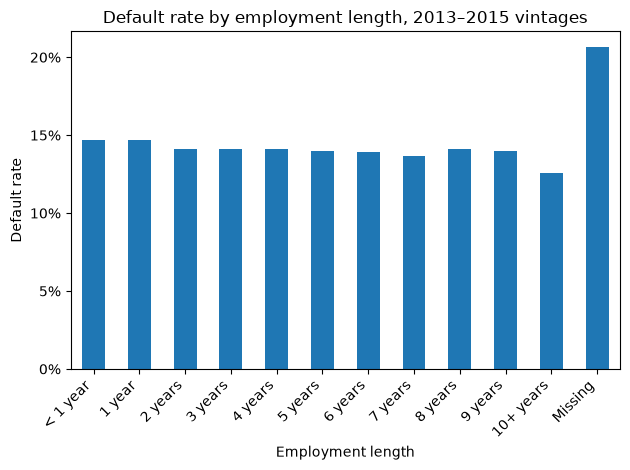

In [ ]:
ax = emp_length_summary["mean"].plot(kind="bar", rot=45)
ax.set_ylabel("Default rate")
ax.set_xlabel("Employment length")
ax.set_title("Default rate by employment length, 2013–2015 vintages")
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout()
plt.show()

In [21]:
verification_summary = (train.groupby("verification_status")["default"]
                   .agg(["mean", "count"])
                   .sort_values("mean"))
verification_summary

,mean,count
verification_status,,
Not Verified,0.115258,181402
Source Verified,0.143467,200674
Verified,0.165578,163850


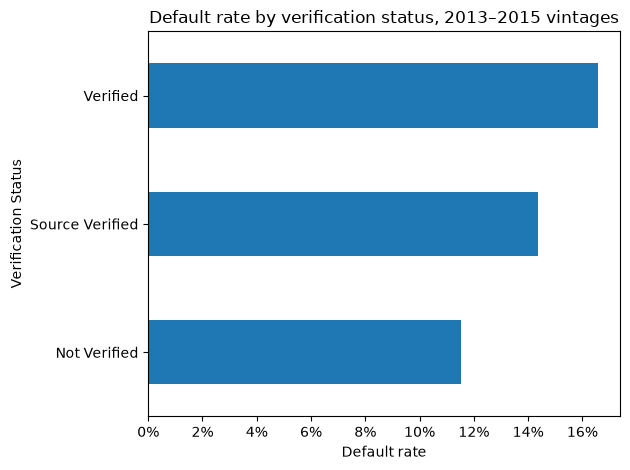

In [52]:
ax = verification_summary["mean"].plot(kind="barh")
ax.set_xlabel("Default rate")
ax.set_ylabel("Verification Status")
ax.set_title("Default rate by verification status, 2013–2015 vintages")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout()
plt.show()

Finding: Verified borrowers default more (16.5% vs. 11.5% not verified), because LC selectively verified riskier-looking applications. The variable reflects lender process, not borrower behavior. Flagged for review in model selection.

In [ ]:
mask = (df["term"] == " 36 months") & (df["issue_d"].dt.year.between(2013, 2017)) & (df["application_type"] == "Individual")
df36 = df[mask].copy()

In [24]:
grade_summary = (train.groupby("grade")["default"]
                 .agg(["mean", "count"])
                 .sort_index())
grade_summary

,mean,count
grade,,
A,0.052953,122504
B,0.111044,185476
C,0.180691,146117
D,0.237417,67712
E,0.291971,19728
F,0.335360,3948
G,0.414966,441


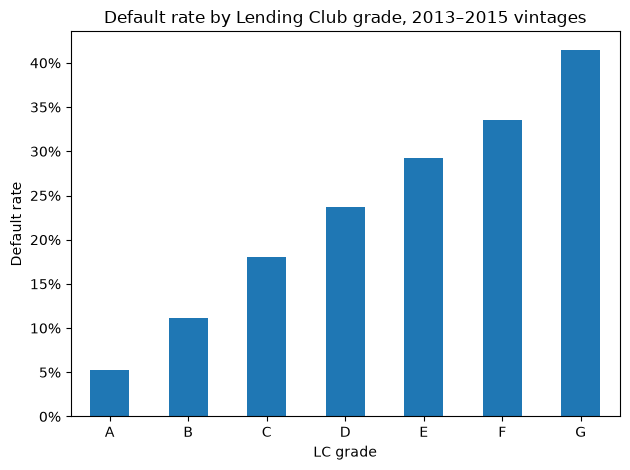

In [29]:
ax = grade_summary["mean"].plot(kind="bar", rot=0)
ax.set_ylabel("Default rate")
ax.set_xlabel("LC grade")
ax.set_title("Default rate by Lending Club grade, 2013–2015 vintages")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.tight_layout()
plt.show()

In [54]:
pd.set_option("display.float_format", "{:,.2f}".format)
train[["annual_inc", "dti"]].describe(percentiles=[0.01, 0.5, 0.99, 0.999])

,annual_inc,dti
count,"545,926.00","545,926.00"
mean,"73,288.78",17.89
std,"66,843.49",8.29
min,"3,000.00",0.00
1%,"17,600.00",2.15
50%,"61,000.00",17.34
99%,"250,000.00",37.37
99.9%,"550,000.00",39.69
max,"9,000,000.00",39.99


Finding: Income is right-skewed (median $61k, 99th pct $250k, max $9M), likely including self-reported errors. DTI is capped at 40 by LC policy with no invalid values. No treatment needed: WoE binning and tree models are both robust to extreme values.